# Assignment: Build and Test a Machine-Learned Interatomic Potential



### Instructions
1. Complete every cell marked `# TODO`. Do **not** change the names or signatures of the functions you are asked to write, because the check cells call them.
2. After each task, run the **check cell** that follows it. A check prints `PASSED` when your implementation is correct. Passing checks is necessary but not sufficient for full marks: plots, tables and written answers are graded too.
3. Only NumPy and Matplotlib are allowed. Do not import ASE, PyTorch, scikit-learn or any MLIP package.
4. Use the practice-session notebook and the class notes as references. Copying code from the practice notebook is allowed **only** where it is marked as provided here. Everything else must be written by you.
5. Submit the executed notebook (`.ipynb`) with all outputs visible.

### The problem
You will build a linear MLIP for an 8-atom cluster described by a reference potential that differs from the one in the practice session: a **Morse** pair potential plus a three-body term that favours **90°** bond angles. All quantities are in reduced units ($D_e=1$, $r_0=1$, $m=1$, $k_B=1$).


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def check(cond, msg=""):
    print("PASSED" if cond else f"FAILED  {msg}")

# ---- provided helpers (same as in the practice session) ----
def pair_geometry(R):
    D = R[None, :, :] - R[:, None, :]
    return D, np.linalg.norm(D, axis=-1)

def numerical_forces(energy_fn, R, h=1e-5):
    F = np.zeros_like(R)
    for i in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[i, a] += h
            Rm = R.copy(); Rm[i, a] -= h
            F[i, a] = -(energy_fn(Rp) - energy_fn(Rm)) / (2 * h)
    return F

def fc_cos(r, rc):
    return np.where(r < rc, 0.5 * (np.cos(np.pi * np.minimum(r, rc) / rc) + 1.0), 0.0)

def random_rotation(rng):
    Q, Rq = np.linalg.qr(rng.normal(size=(3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(Rq)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q

rng = np.random.default_rng(2026)

---
## Task A. Morse potential: energy and analytic forces
$$
V(r)=D_e\Big[\big(1-e^{-a(r-r_0)}\big)^2-1\Big],\qquad E_{\rm Morse}=\sum_{i<j}V(r_{ij})
$$

with $D_e=1$, $a=3$, $r_0=1$.

**A1 (3 pts).** Show by hand (write it in the markdown cell below) that $V(r_0)=-D_e$ and that

$$
V'(r)=2aD_e\,e^{-a(r-r_0)}\big(1-e^{-a(r-r_0)}\big).
$$

**A2 (7 pts).** Implement `morse_energy(R)` and `morse_forces(R)`. The force must be **analytic** (use $\mathbf F_i=\sum_{j\ne i}V'(r_{ij})\,\mathbf d_{ij}/r_{ij}$ with $\mathbf d_{ij}=\mathbf r_j-\mathbf r_i$). Do not call `numerical_forces` inside `morse_forces`.

### A1. Derivation

1. **Value at $r = r_0$**:
   $$V(r_0) = D_e \Big[ \big(1 - e^{-a(r_0 - r_0)}\big)^2 - 1 \Big] = D_e \Big[ \big(1 - e^0\big)^2 - 1 \Big] = D_e \big[ (1 - 1)^2 - 1 \big] = -D_e$$
   Since $D_e = 1$, we have $V(r_0) = -1$.

2. **Derivative $V'(r)$**:
   Let $u(r) = 1 - e^{-a(r-r_0)}$. Then $V(r) = D_e (u(r)^2 - 1)$.
   By the chain rule:
   $$V'(r) = D_e \cdot 2u(r) \cdot u'(r)$$
   The derivative of $u(r)$ with respect to $r$ is:
   $$u'(r) = - e^{-a(r-r_0)} \cdot (-a) = a e^{-a(r-r_0)}$$
   Substituting $u(r)$ and $u'(r)$ back into the expression for $V'(r)$:
   $$V'(r) = 2aD_e e^{-a(r-r_0)} \big(1 - e^{-a(r-r_0)}\big)$$

In [8]:
D_E, A_M, R0_M = 1.0, 3.0, 1.0

def morse_energy(R):
    _, r = pair_geometry(R)
    N = R.shape[0]
    # Mask out diagonal/self-interaction terms
    mask = np.triu(np.ones((N, N), dtype=bool), k=1)
    r_pairs = r[mask]

    v_r = D_E * ((1.0 - np.exp(-A_M * (r_pairs - R0_M)))**2 - 1.0)
    return np.sum(v_r)

def morse_forces(R):
    D, r = pair_geometry(R)
    N = R.shape[0]
    forces = np.zeros_like(R)

    for i in range(N):
        for j in range(N):
            if i != j:
                rij = r[i, j]
                dij = D[i, j]
                v_prime = 2 * A_M * D_E * np.exp(-A_M * (rij - R0_M)) * (1.0 - np.exp(-A_M * (rij - R0_M)))
                forces[i] += v_prime * dij / rij
    return forces

In [9]:
# ---- check A ----
dimer = np.array([[0.0, 0, 0], [1.0, 0, 0]])
check(np.isclose(morse_energy(dimer), -1.0), "V(r0) should be -1")
dimer2 = np.array([[0.0, 0, 0], [1.3, 0, 0]])
y = np.exp(-3 * 0.3)
check(np.isclose(morse_energy(dimer2), (1 - y)**2 - 1), "dimer energy at r = 1.3")
Rt = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + rng.normal(scale=0.08, size=(8, 3))
err = np.abs(morse_forces(Rt) - numerical_forces(morse_energy, Rt)).max()
check(err < 1e-6, f"analytic vs numerical force difference = {err:.2e}")
check(np.allclose(morse_forces(Rt).sum(0), 0, atol=1e-10), "forces must sum to zero (Newton's third law)")

PASSED
PASSED
PASSED
PASSED


---
## Task B. Polynomial envelope cutoff
Implement the envelope used by DimeNet, NequIP and MACE:

$$
f_{\rm env}(r)=1-\frac{(p+1)(p+2)}{2}x^{p}+p(p+2)\,x^{p+1}-\frac{p(p+1)}{2}x^{p+2},\qquad x=\frac{r}{r_c},
$$

and $f_{\rm env}=0$ for $r\ge r_c$. The function must accept NumPy arrays of any shape.

In [10]:
def f_env(r, rc, p=6):
    x = np.minimum(r / rc, 1.0)
    term1 = 1.0
    term2 = -0.5 * (p + 1) * (p + 2) * (x**p)
    term3 = p * (p + 2) * (x**(p + 1))
    term4 = -0.5 * p * (p + 1) * (x**(p + 2))

    result = term1 + term2 + term3 + term4
    return np.where(r < rc, result, 0.0)

In [11]:
# ---- check B ----
rc, h = 2.0, 1e-4
check(np.isclose(f_env(0.0, rc), 1.0), "f(0) = 1")
check(abs(f_env(rc - 1e-9, rc)) < 1e-12, "f(rc) = 0")
slope = (f_env(rc - h, rc) - f_env(rc - 3*h, rc)) / (2*h)
check(abs(slope) < 1e-6, f"slope near rc = {slope:.2e}")
check(f_env(np.ones((3, 4)) * 0.5, rc).shape == (3, 4), "must work on arrays")
check(np.isclose(f_env(1.0, 2.0), 1 - 28/64 + 48/128 - 21/256), "value at x = 0.5")

PASSED
PASSED
PASSED
PASSED
PASSED


---
## Task C. Behler symmetry functions
Implement, **for every atom $i$ at once**,

$$
G_i^{2}(\eta,R_s)=\sum_{j\ne i}e^{-\eta(r_{ij}-R_s)^2}f_c(r_{ij}),
$$
$$
G_i^{4}(\eta,\zeta,\lambda)=2^{1-\zeta}\sum_{j<k;\ j,k\ne i}(1+\lambda\cos\theta_{jik})^{\zeta}\,e^{-\eta(r_{ij}^2+r_{ik}^2+r_{jk}^2)}\,f_c(r_{ij})f_c(r_{ik})f_c(r_{jk}),
$$

using the cosine cutoff `fc_cos` provided above. Note: the sum counts each unordered pair $\{j,k\}$ **once**.

- `g2_atoms(R, etas, Rss, rc)` returns an array of shape `(N, len(etas))`, where column $m$ uses $(\eta_m, R_{s,m})$.
- `g4_atoms(R, params, rc)` returns shape `(N, len(params))`, where `params` is a list of tuples `(eta, zeta, lam)`.

Loops over atoms are allowed, but vectorised code (as in the practice notebook) runs about 50 times faster and makes Tasks F to H much quicker.

In [2]:
def g2_atoms(R, etas, Rss, rc):
    N = R.shape[0]
    _, r = pair_geometry(R)
    # Mask self-interaction
    np.fill_diagonal(r, np.inf)

    # r shape: (N, N), etas: (M,), Rss: (M,)
    # We want output of shape (N, M)
    fc = fc_cos(r, rc) # (N, N)

    # Compute exponents: (N, N, M)
    r_diff = r[:, :, None] - Rss[None, None, :]
    gaussian = np.exp(-etas[None, None, :] * (r_diff**2))

    # Multiply by cutoff and sum over j
    g2 = gaussian * fc[:, :, None]
    return np.sum(g2, axis=1)

def g4_atoms(R, params, rc):
    N = R.shape[0]
    D, r = pair_geometry(R)

    fc = fc_cos(r, rc)
    np.fill_diagonal(r, np.inf)

    # Unit vectors for angles
    u = D / r[:, :, None]
    # Cosine of angles theta_jik
    cos_theta = np.einsum('ijx,ikx->ijk', u, u)

    # Exponential term components
    r2 = r**2
    r2_sum = r2[:, :, None] + r2[:, None, :] # r_ij^2 + r_ik^2
    fc_prod = fc[:, :, None] * fc[:, None, :]

    num_params = len(params)
    g4 = np.zeros((N, num_params))

    for m, (eta, zeta, lam) in enumerate(params):
        # 2^(1-zeta) * (1 + lambda * cos_theta)^zeta
        ang = 2.0**(1.0 - zeta) * (1.0 + lam * cos_theta)**zeta

        # exp(-eta * (r_ij^2 + r_ik^2 + r_jk^2))
        # r_jk^2 is r2[j, k], which we can broadcast or construct as (N, N, N)
        r2_jk = r2[None, :, :]
        rad = np.exp(-eta * (r2_sum + r2_jk))

        # Combine terms
        terms = ang * rad * fc_prod * fc[None, :, :]

        # We need sum over j < k with j, k != i
        # Let's zero out self terms where j == k or i == j or i == k
        idx = np.arange(N)
        terms[:, idx, idx] = 0.0

        g4[:, m] = 0.5 * np.sum(terms, axis=(1, 2))

    return g4

In [12]:
# ---- check C: Example 3 of the class notes ----
th = np.deg2rad(104.5)
R3 = np.array([[0, 0, 0], [1.0, 0, 0], [1.5*np.cos(th), 1.5*np.sin(th), 0]])
G2 = g2_atoms(R3, np.array([0.5]), np.array([0.0]), 5.0)
G4 = g4_atoms(R3, [(0.1, 1, 1), (0.1, 1, -1)], 5.0)
check(G2.shape == (3, 1) and G4.shape == (3, 2), "output shapes")
check(np.isclose(G2[0, 0], 0.80635, atol=1e-4), f"G2 of atom 0 = {G2[0,0]:.5f}, expected 0.80635")
check(np.allclose(G4[0], [0.17059, 0.28455], atol=1e-4), f"G4 of atom 0 = {G4[0]}, expected [0.17059 0.28455]")
# a second test with more atoms, against a slow but obvious reference implementation
def g4_slow(R, eta, zeta, lam, rc):
    N = len(R); out = np.zeros(N)
    for i in range(N):
        for j in range(N):
            for k in range(j + 1, N):
                if i in (j, k): continue
                a, b = R[j] - R[i], R[k] - R[i]; rij, rik, rjk = np.linalg.norm(a), np.linalg.norm(b), np.linalg.norm(R[k] - R[j])
                c = a @ b / (rij * rik)
                out[i] += 2**(1-zeta) * (1 + lam*c)**zeta * np.exp(-eta*(rij**2 + rik**2 + rjk**2)) * fc_cos(rij, rc) * fc_cos(rik, rc) * fc_cos(rjk, rc)
    return out
check(np.allclose(g4_atoms(Rt, [(0.5, 2, -1)], 2.0)[:, 0], g4_slow(Rt, 0.5, 2, -1, 2.0)), "G4 on the 8-atom test cube")

PASSED
PASSED
PASSED
PASSED


---
## Task D. Invariance tests
**D1 (6 pts).** Write `invariance_errors(desc_fn, R, rng)` that applies (i) a random rotation, (ii) a reflection $z\to-z$, (iii) a random translation and (iv) a random permutation of atoms to the configuration `R`. The function must return a dictionary with keys `"rotation"`, `"reflection"`, `"translation"`, `"permutation"` and, as values, the maximum absolute difference between the descriptors before and after each operation. Remember that a permutation reorders the rows of the descriptor matrix.

**D2 (4 pts).** A student proposes the "descriptor" $\mathbf q_i=\sum_{j\ne i}(\mathbf r_j-\mathbf r_i)\,f_c(r_{ij})$, a 3-component vector per atom. Use your function to test it and explain the result in one or two sentences. Which category of the notes (invariant or equivariant) does it belong to?

In [ ]:
def invariance_errors(desc_fn, R, rng):
    # 1. Original descriptor
    d0 = desc_fn(R)
    N = R.shape[0]

    # 2. Rotation
    Q = random_rotation(rng)
    R_rot = R @ Q.T
    d_rot = desc_fn(R_rot)
    err_rot = np.abs(d_rot - d0).max()

    # 3. Reflection z -> -z
    R_ref = R.copy()
    R_ref[:, 2] *= -1.0
    d_ref = desc_fn(R_ref)
    err_ref = np.abs(d_ref - d0).max()

    # 4. Translation
    t = rng.normal(size=(1, 3))
    R_trans = R + t
    d_trans = desc_fn(R_trans)
    err_trans = np.abs(d_trans - d0).max()

    # 5. Permutation
    p = rng.permutation(N)
    R_perm = R[p]
    d_perm = desc_fn(R_perm)
    # Since the descriptor matrix rows are reordered under permutation,
    # we reorder them back to compare directly with d0
    inv_p = np.argsort(p)
    err_perm = np.abs(d_perm[inv_p] - d0).max()

    return {
        "rotation": float(err_rot),
        "reflection": float(err_ref),
        "translation": float(err_trans),
        "permutation": float(err_perm)
    }

def student_vector_descriptor(R, rc=2.5):
    D, r = pair_geometry(R)
    return np.sum(D * fc_cos(r, rc)[:, :, None], axis=1)

# Run the test for the student descriptor
Rt_test = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float) + np.random.default_rng(2026).normal(scale=0.08, size=(8, 3))
student_errs = invariance_errors(student_vector_descriptor, Rt_test, np.random.default_rng(0))
print("Student vector descriptor errors:")
for k, v in student_errs.items():
    print(f"  {k}: {v:.1e}")

In [13]:
# ---- check D1 ----
desc_test = lambda X: np.hstack([g2_atoms(X, np.full(6, 4.0), np.linspace(0.8, 2.2, 6), 2.5),
                                 g4_atoms(X, [(0.5, 1, 1), (0.5, 4, -1)], 2.5)])
errs = invariance_errors(desc_test, Rt, np.random.default_rng(0))
print({k: f"{v:.1e}" for k, v in errs.items()})
check(set(errs) == {"rotation", "reflection", "translation", "permutation"}, "dictionary keys")
check(max(errs.values()) < 1e-10, "G2/G4 must be invariant under all four operations")
bad = lambda X: X.copy()   # raw coordinates as a 'descriptor'
e_bad = invariance_errors(bad, Rt, np.random.default_rng(0))
check(e_bad["rotation"] > 1e-3 and e_bad["translation"] > 1e-3, "your function must detect non-invariant descriptors")

{'rotation': '1.8e-15', 'reflection': '0.0e+00', 'translation': '1.3e-15', 'permutation': '8.9e-16'}
PASSED
PASSED
PASSED


**D2. Your explanation:**

The student's descriptor is **equivariant** under rotation and reflection, meaning that when the atomic coordinates are rotated or reflected, the resulting descriptor vectors rotate or reflect by the exact same transformation instead of remaining unchanged. It is, however, **invariant** under translation because it only depends on the relative displacement vectors $\mathbf{r}_j - \mathbf{r}_i$ between atoms.

---
## Task E. The reference potential and dataset

The reference potential (provided) is

$$
E_{\rm ref}=E_{\rm Morse}+\frac{K}{2}\sum_i\sum_{j\ne k}\big(\cos\theta_{jik}-c_0\big)^2\,g(r_{ij})\,g(r_{ik}),\qquad K=0.6,\ c_0=0,\ g(r)=f_c^{\cos}(r;1.4).
$$

With $c_0=0$ the three-body term favours right angles. The cell below relaxes a cube of 8 atoms and samples 360 configurations with Langevin MD at $T=0.05,\ 0.15,\ 0.25$. **Run it as given** (it uses your Morse functions and takes about 30 s).

In [14]:
# ---- provided: reference potential, relaxation, Langevin sampling ----
def three_body_energy(R, K=0.6, c0=0.0, rc3=1.4):
    D, r = pair_geometry(R); N = len(R)
    np.fill_diagonal(r, np.inf)
    g = fc_cos(r, rc3); u = D / r[:, :, None]
    cos = np.einsum("ijx,ikx->ijk", u, u)
    t = (cos - c0)**2 * g[:, :, None] * g[:, None, :]
    idx = np.arange(N); t[:, idx, idx] = 0.0
    return 0.5 * K * t.sum()

def ref_energy(R): return morse_energy(R) + three_body_energy(R)
def ref_forces(R): return morse_forces(R) + numerical_forces(three_body_energy, R)

def relax(R, efun, ffun, fmax=1e-4, maxit=5000):
    R = R.copy(); step = 0.01; E = efun(R)
    for _ in range(maxit):
        F = ffun(R)
        if np.abs(F).max() < fmax: break
        Rn = R + step * F; En = efun(Rn)
        if En < E: R, E = Rn, En; step *= 1.1
        else: step *= 0.5
    return R

def langevin(R, ffun, T, nsteps, dt=0.005, gamma=1.0, every=40, rng=None):
    R = R.copy(); v = rng.normal(scale=np.sqrt(T), size=R.shape); v -= v.mean(0)
    F = ffun(R); c1 = np.exp(-gamma * dt); c2 = np.sqrt((1 - c1**2) * T); frames = []
    for s in range(nsteps):
        v += 0.5 * dt * F; R += 0.5 * dt * v
        v = c1 * v + c2 * rng.normal(size=R.shape)
        R += 0.5 * dt * v; F = ffun(R); v += 0.5 * dt * F
        if (s + 1) % every == 0: frames.append(R.copy())
    return frames

cube = np.array([[i, j, k] for i in (0, 1) for j in (0, 1) for k in (0, 1)], float)
R_min = relax(cube, ref_energy, ref_forces)
N_at = len(R_min)
print(f"relaxed cluster energy: {ref_energy(R_min):.4f}")

t0 = time.time(); rng_md = np.random.default_rng(11)
configs, energies, forces, temps = [], [], [], []
for T in (0.05, 0.15, 0.25):
    for X in langevin(R_min, ref_forces, T, 4800, rng=rng_md):
        configs.append(X); energies.append(ref_energy(X)); forces.append(ref_forces(X)); temps.append(T)
configs, energies, forces, temps = map(np.array, (configs, energies, forces, temps))
print(f"{len(configs)} configurations generated in {time.time()-t0:.1f} s")

relaxed cluster energy: -20.0799
360 configurations generated in 78.4 s


**E1 (5 pts).** (a) Plot histograms of the energy per atom for the three temperatures in one figure. (b) Print the shortest and longest interatomic distance found in the whole dataset, and the largest distance of any atom from the cluster centre of mass. (c) In one sentence: did the cluster stay intact at $T=0.25$? Justify with your numbers.

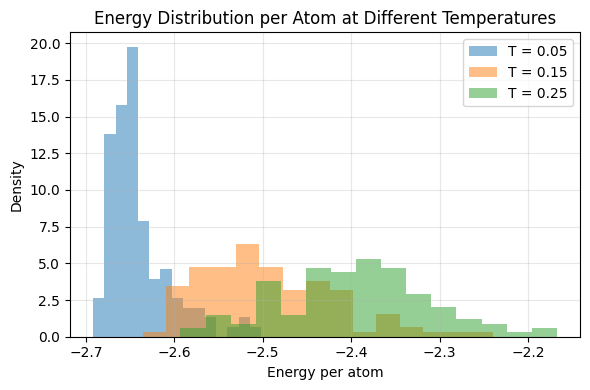

Shortest interatomic distance: 0.7342
Longest interatomic distance: 2.4005
Largest distance of any atom from COM: 1.3699


In [15]:
# ---- Task E1 (a) and (b) ----
# (a) Plot energy per atom histograms
plt.figure(figsize=(6, 4))
for T in (0.05, 0.15, 0.25):
    mask = (temps == T)
    plt.hist(energies[mask] / N_at, bins=15, alpha=0.5, label=f"T = {T}", density=True)
plt.xlabel("Energy per atom")
plt.ylabel("Density")
plt.title("Energy Distribution per Atom at Different Temperatures")
plt.legend()
plt.tight_layout()
plt.show()

# (b) Shortest/longest distance and maximum COM distance
all_distances = []
max_com_dist = 0.0

for R in configs:
    _, r = pair_geometry(R)
    # Extact upper triangle pairwise distances
    mask = np.triu(np.ones_like(r, dtype=bool), k=1)
    all_distances.extend(r[mask])

    # COM distance
    com = R.mean(axis=0)
    com_dists = np.linalg.norm(R - com, axis=-1)
    max_com_dist = max(max_com_dist, com_dists.max())

all_distances = np.array(all_distances)
print(f"Shortest interatomic distance: {all_distances.min():.4f}")
print(f"Longest interatomic distance: {all_distances.max():.4f}")
print(f"Largest distance of any atom from COM: {max_com_dist:.4f}")

**E1 (c). Your answer:**

Yes, the cluster stayed intact at $T=0.25$ because the largest distance of any atom from the center of mass was only $1.37$ (which is close to the typical interatomic bond distance of $1.0$), and the longest interatomic distance in the entire dataset was only $2.40$, showing that no atoms evaporated or dissociated from the cluster.

---
## Task F. A linear MLIP trained on energies and forces

Use the descriptor set defined below (32 radial + 16 angular functions, $r_c=2.5$) and the **provided** Jacobian routine.

The model is $E=Nb+\mathbf w\cdot\sum_i\tilde{\mathbf G}_i$ with standardised descriptors $\tilde G_{i\mu}=(G_{i\mu}-\mu_\mu)/s_\mu$, and forces $\mathbf F_k=-\sum_\mu w_\mu\,\partial(\sum_i\tilde G_{i\mu})/\partial\mathbf r_k$.

**F1 (10 pts).** Implement
- `fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8)`: builds the least-squares system described in §7.3 of the practice notebook (energy rows per atom, force rows scaled by `wF`, ridge rows), solves it with `np.linalg.lstsq`, and returns a dictionary with keys `"b"`, `"w"`, `"mu"`, `"sd"`, `"cols"`. Here `idx` are training indices and `cols` the descriptor columns to use. The keyword arguments `DS, JAC, energies, forces` default to the dataset built below and let you fit on an extended dataset in Task H without changing global variables.
- `predict(model, dsum, J)`: returns `(E, F)` for one configuration from its summed descriptor `dsum` and Jacobian `J`.
- `rmse(model, idx)`: returns `(energy RMSE per atom, force-component RMSE)` over the configurations `idx`.

**F2 (10 pts).** Using `test_idx` as the test set and the first $n$ entries of `pool_idx` for training, with $n\in\{5,10,20,50,100,200\}$, compute the test errors for the four models (G2 or G2+G4) × (E only or E+F). Print a table and plot both learning curves on log–log axes. Then answer the questions in the markdown cell that follows.

In [ ]:
# ---- provided: descriptor set and Jacobians ----
RC = 2.5
ETAS = np.full(32, 16.0); RSS = np.linspace(0.6, 2.4, 32)
G4P = [(eta, zeta, lam) for eta in (0.3, 1.5) for zeta in (1, 2, 4, 16) for lam in (1, -1)]
N_G2, N_G4 = len(ETAS), len(G4P)
cols_G2 = np.arange(N_G2); cols_all = np.arange(N_G2 + N_G4)

def descriptors(R):
    return np.hstack([g2_atoms(R, ETAS, RSS, RC), g4_atoms(R, G4P, RC)])

def descriptor_sum_and_jacobian(R, desc_fn=descriptors, h=1e-5):
    d0 = desc_fn(R).sum(axis=0); J = np.zeros((d0.size,) + R.shape)
    for k in range(R.shape[0]):
        for a in range(3):
            Rp = R.copy(); Rp[k, a] += h; Rm = R.copy(); Rm[k, a] -= h
            J[:, k, a] = (desc_fn(Rp).sum(0) - desc_fn(Rm).sum(0)) / (2 * h)
    return d0, J

t0 = time.time()
DS, JAC = map(np.array, zip(*[descriptor_sum_and_jacobian(X) for X in configs]))
print(f"DS {DS.shape}, JAC {JAC.shape}, {time.time()-t0:.1f} s")
perm_all = np.random.default_rng(0).permutation(len(configs))
test_idx, pool_idx = perm_all[:100], perm_all[100:]

In [ ]:
def fit_linear_mlip(idx, cols, use_forces=True, wF=1.0, ridge=1e-8, DS=DS, JAC=JAC, energies=energies, forces=forces):
    # TODO
    raise NotImplementedError

def predict(model, dsum, J):
    # TODO: return E, F
    raise NotImplementedError

def rmse(model, idx, DS=DS, JAC=JAC, energies=energies, forces=forces):
    # TODO: return energy RMSE per atom, force-component RMSE
    raise NotImplementedError

In [ ]:
# ---- check F1 ----
m_chk = fit_linear_mlip(pool_idx[:50], cols_all, use_forces=True)
check(set(m_chk) >= {"b", "w", "mu", "sd", "cols"}, "model dictionary keys")
E_chk, F_chk = predict(m_chk, DS[test_idx[0]], JAC[test_idx[0]])
check(np.shape(F_chk) == (N_at, 3), "force shape")
check(np.allclose(F_chk.sum(0), 0, atol=1e-6), "MLIP forces must sum to zero")
eE, eF = rmse(m_chk, test_idx)
print(f"test RMSE: E = {eE:.2e} per atom, F = {eF:.3f}   (force std = {forces.std():.2f})")
check(eF < 0.1 * forces.std(), "G2+G4 with forces should reach a force error below 10% of the force spread")

In [ ]:
# TODO F2: learning curves (table + log-log plot)

**F2 questions.** (a) How many training configurations does the G2+G4, E+F model need to beat the force error of the G2+G4, E-only model trained on 200 configurations? (b) Why does the G2-only model stop improving? Relate your answer to the form of $E_{\rm ref}$. (c) Count the number of scalar labels (energies plus force components) in 10 configurations and compare it with the number of model parameters.

*(write here)*

---
## Task G. Molecular dynamics with your MLIP

**G1 (7 pts).** Implement `velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3)` where `ef(R)` returns `(E, F)`. Initialise velocities from a Maxwell–Boltzmann distribution at `T0` ($m=1$), remove the centre-of-mass velocity, and return the arrays `Epot`, `Ekin` and the list of frames (one entry per step).

**G2 (8 pts).** Train the final model (G2+G4, E+F, all 260 pool configurations). Starting from `configs[test_idx[0]]` with $T_0=0.2$, run 1500 NVE steps with the MLIP and with the reference potential. Plot the total energy of both runs versus time. Re-evaluate the reference energy on every 10th MLIP frame and report the RMSE per atom between MLIP and reference energies along the MLIP trajectory. Comment in two sentences.

In [ ]:
def velocity_verlet(R, ef, T0, nsteps, dt=0.005, seed=3):
    # TODO
    raise NotImplementedError

# TODO G2

In [ ]:
# ---- check G1 ----
k = 0.5; harm = lambda X: (0.5 * k * np.sum(X**2), -k * X)        # 3D harmonic oscillators
Ep_h, Ek_h, fr_h = velocity_verlet(np.ones((2, 3)), harm, 0.5, 2000, dt=0.01)
Et_h = Ep_h + Ek_h
check(len(fr_h) == 2000 and Ep_h.shape == (2000,), "output lengths")
check(Et_h.std() / Et_h.mean() < 1e-3, f"harmonic test: relative energy fluctuation {Et_h.std()/Et_h.mean():.1e}")

**G2 comment:**

---
## Task H. Extrapolation and a data-driven fix
**H1 (4 pts).** Scale the centred minimum structure `R_min` uniformly by $s\in[0.75,1.25]$ (25 values). Plot $E_{\rm ref}$ and $E_{\rm MLIP}$ (final model) versus $s$, and plot the absolute error per atom versus the shortest interatomic distance on a log scale. Mark the shortest distance present in the training set.

**H2 (6 pts).** Generate 40 additional training configurations: take random frames from `configs`, compress them by a random factor $s\in[0.75,0.95]$, and add Gaussian noise with standard deviation 0.03. Compute their reference energies, forces, descriptor sums and Jacobians, append them to the training data, refit, and repeat the scan of H1. Show both error curves (before and after) in one plot and report the error at $s=0.8$ for both models. Has the accuracy near equilibrium changed? Check with `rmse` on the original `test_idx`. Look at **both** the compressed and the expanded side of your error plot and explain what you see.

In [ ]:
# TODO H1

# TODO H2

**H2 comment:**

---
## Task I. Written questions
Answer briefly (three to five sentences each).

1. The atomic energy $E_i$ in Eq. $E=\sum_iE_i$ is not a quantum-mechanical observable. Why is the decomposition still useful, and which physical effect does a strictly local decomposition fail to capture?
2. Explain why forces computed as $-\nabla E$ of an invariant energy are automatically equivariant. Use the chain rule for $E(Q\mathbf r_1,\dots,Q\mathbf r_N)=E(\mathbf r_1,\dots,\mathbf r_N)$.
3. A message-passing model has $T=3$ layers and $r_c=5$ Å. What is its receptive field? Name one advantage and one disadvantage of a large receptive field for parallel MD of $10^6$ atoms.
4. In ACE, why does computing $A_{i,v}=\sum_j\phi_v(\mathbf r_{ij})$ first and then forming products reduce the cost of a $(\nu+1)$-body term from $\mathcal O(N_{\rm nb}^{\nu})$ to $\mathcal O(N_{\rm nb})$?
5. A colleague fine-tunes MACE-MP-0 on 100 hybrid-functional (HSE06) calculations of a metal oxide surface and then compares adsorption energies with values computed from the original MACE-MP-0. Identify two pitfalls.

**Your answers:**

1.

2.

3.

4.

5.

---
## Bonus. A power-spectrum (SOAP-like) descriptor

Replace the 16 $G^4$ functions by the 3-body power spectrum written through the addition theorem (§12 of the notes):

$$
p_{i,nl}=\frac{2l+1}{4\pi}\sum_{j\ne i}\sum_{k\ne i}R_n(r_{ij})\,R_n(r_{ik})\,P_l(\cos\theta_{jik}),\qquad R_n(r)=e^{-\eta_n r^2}f_c(r),
$$

with $l=0,1,2,3$, Legendre polynomials $P_l$, and four radial functions $\eta_n\in\{0.3,0.8,1.5,3.0\}$ (16 features in total). Note that the double sum includes $j=k$, as in ACE. Build the descriptor `G2 + power spectrum`, compute the Jacobians, fit an E+F model on the full pool, and compare its test errors with G2+G4. Verify numerically that $p_{i,n1}=|\mathbf A_{i,n1}|^2$ for one atom, where $\mathbf A_{i,n1}=\sqrt{3/4\pi}\sum_jR_n(r_{ij})\hat{\mathbf r}_{ij}$.